In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
plt.style.use('ggplot')


In [4]:
pd.set_option('display.max_columns', 200)

In [5]:
df = pd.read_csv('datasets/NCRB_CII-2019_Table_19B.2.csv')

In [7]:
df.shape

(20, 20)

In [8]:
df.head(20)

,S. No,City,Juveniles Apprehended - Boys,Juveniles Apprehended - Girls,Juveniles Apprehended - Total,18 and above and below 30 years - Male,18 and above and below 30 years - Female,18 and above and below 30 years - Total,30 and above and below 45 years - Male,30 and above and below 45 years - Female,30 and above and below 45 years - Total,45 and above and below 60 years - Male,45 and above and below 60 years - Female,45 and above and below 60 years - Total,60 years and above - Male,60 years and above - Female,60 years and above - Total,Total - Male,Total - Female,Total - Total Persons Arrested by age and Sex
0,1,Ahmedabad (Gujarat),298,0,298,14488,950,15438,12385,1290,13675,4264,668,4932,463,146,609,31898,3054,34952
1,2,Bengaluru(Karnataka),197,3,200,13577,579,14156,9602,974,10576,2531,381,2912,430,84,514,26337,2021,28358
2,3,Chennai(Tamil Nadu),816,0,816,13717,1117,14834,21194,2577,23771,16070,917,16987,2007,93,2100,53804,4704,58508
3,4,Coimbatore(Tamil Nadu),35,0,35,3248,488,3736,2674,293,2967,759,189,948,224,62,286,6940,1032,7972
4,5,Delhi,3073,2,3075,54129,1003,55132,30474,834,31308,8769,266,9035,514,22,536,96959,2127,99086
5,6,Ghaziabad(Uttar Pradesh),0,0,0,1192,5,1197,2241,1,2242,837,1,838,0,0,0,4270,7,4277
6,7,Hyderabad(Telangana),377,0,377,2839,150,2989,3376,129,3505,1197,30,1227,101,1,102,7890,310,8200
7,8,Indore(Madhya Pradesh),275,6,281,5396,248,5644,2873,198,3071,635,74,709,52,11,63,9231,537,9768
8,9,Jaipur(Rajasthan),404,1,405,7630,491,8121,4533,474,5007,2421,250,2671,121,19,140,15109,1235,16344
9,10,Kanpur(Uttar Pradesh),9,0,9,5360,52,5412,2228,17,2245,752,7,759,0,0,0,8349,76,8425


In [11]:
df = df[:-1]

In [ ]:
# dataset summary
print("Dataset Info:")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nBasic Statistics:")
print(df.describe())

Dataset Info:
Shape: (19, 20)
Columns: ['S. No', 'City', ' Juveniles Apprehended - Boys', ' Juveniles Apprehended - Girls', ' Juveniles Apprehended - Total', '18 and above and below 30 years - Male', '18 and above and below 30 years - Female', '18 and above and below 30 years - Total', '30 and above and below 45 years - Male', '30 and above and below 45 years - Female', '30 and above and below 45 years - Total', '45 and above and below 60 years - Male', '45 and above and below 60 years - Female', '45 and above and below 60 years - Total', '60 years and above - Male', '60 years and above - Female', '60 years and above - Total', 'Total   - Male', 'Total   - Female', 'Total   - Total Persons Arrested by age and Sex']

Data Types:
S. No                                              object
City                                               object
 Juveniles Apprehended - Boys                       int64
 Juveniles Apprehended - Girls                      int64
 Juveniles Apprehended - Total 

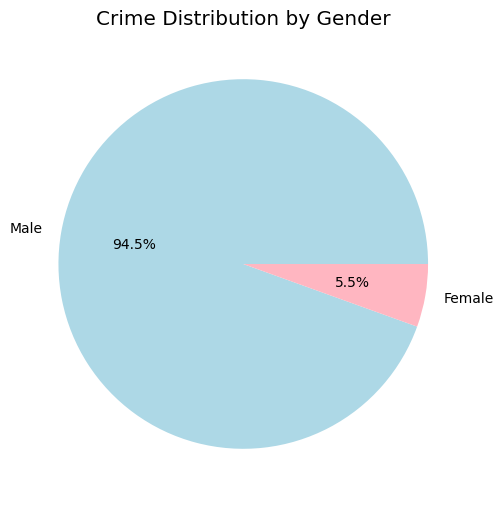

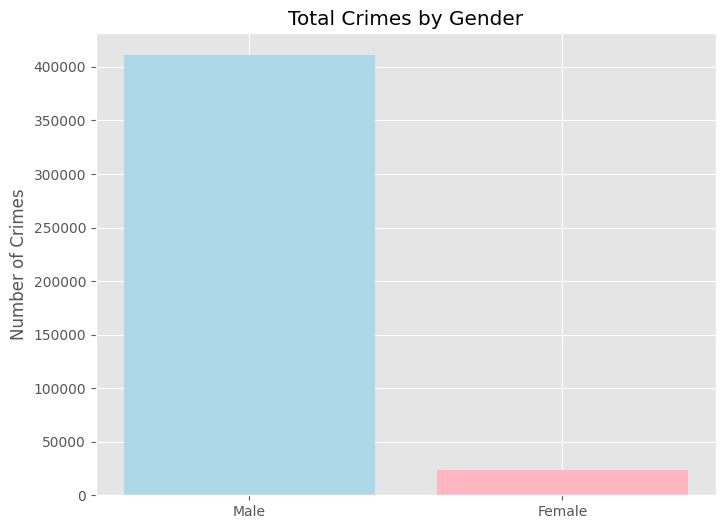

Male crimes: 410,850
Female crimes: 23,919
Gender ratio (M:F): 17.18:1


In [13]:
# Calculate total crimes by gender
male_crimes = df['Total   - Male'].sum()
female_crimes = df['Total   - Female'].sum()

# Create gender comparison
gender_data = {
    'Male': male_crimes,
    'Female': female_crimes
}

# Pie chart for gender distribution
plt.figure(figsize=(10, 6))
plt.pie(gender_data.values(), labels=gender_data.keys(), autopct='%1.1f%%', 
        colors=['lightblue', 'lightpink'])
plt.title('Crime Distribution by Gender')
plt.show()

# Bar chart for better comparison
plt.figure(figsize=(8, 6))
plt.bar(gender_data.keys(), gender_data.values(), color=['lightblue', 'lightpink'])
plt.title('Total Crimes by Gender')
plt.ylabel('Number of Crimes')
plt.show()

print(f"Male crimes: {male_crimes:,}")
print(f"Female crimes: {female_crimes:,}")
print(f"Gender ratio (M:F): {male_crimes/female_crimes:.2f}:1")

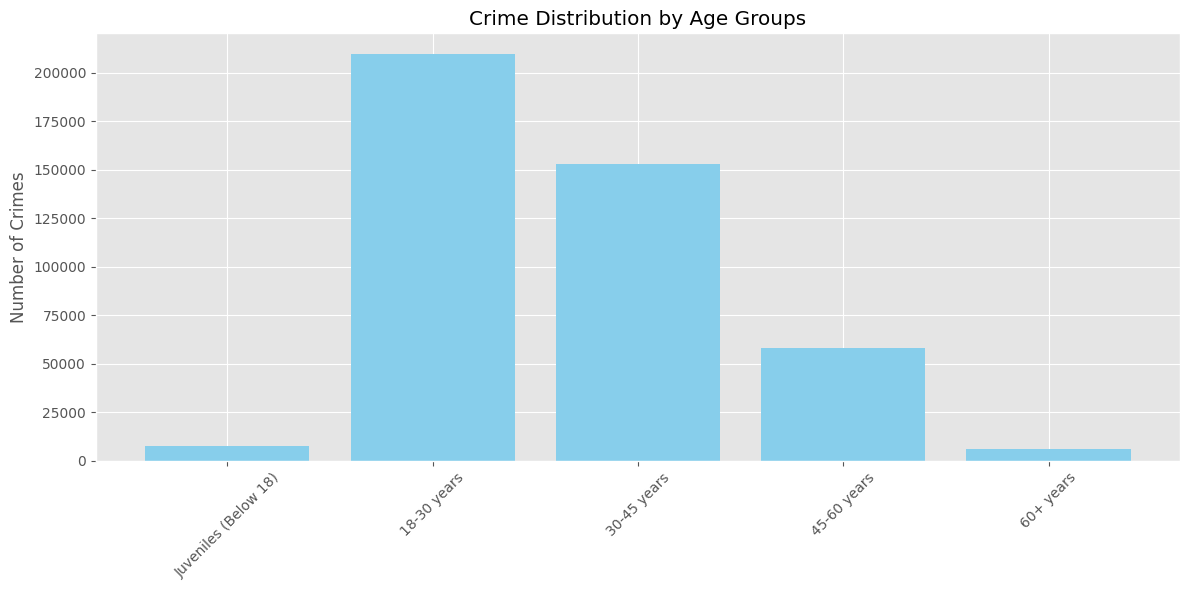

In [17]:
# Age group analysis
age_groups = {
    'Juveniles (Below 18)': df[' Juveniles Apprehended - Boys'].sum() + df[' Juveniles Apprehended - Girls'].sum(),
    '18-30 years': df['18 and above and below 30 years - Total'].sum(),
    '30-45 years': df['30 and above and below 45 years - Total'].sum(),
    '45-60 years': df['45 and above and below 60 years - Total'].sum(),
    '60+ years': df['60 years and above - Total'].sum()
}

# Age group distribution
plt.figure(figsize=(12, 6))
plt.bar(age_groups.keys(), age_groups.values(), color='skyblue')
plt.title('Crime Distribution by Age Groups')
plt.ylabel('Number of Crimes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

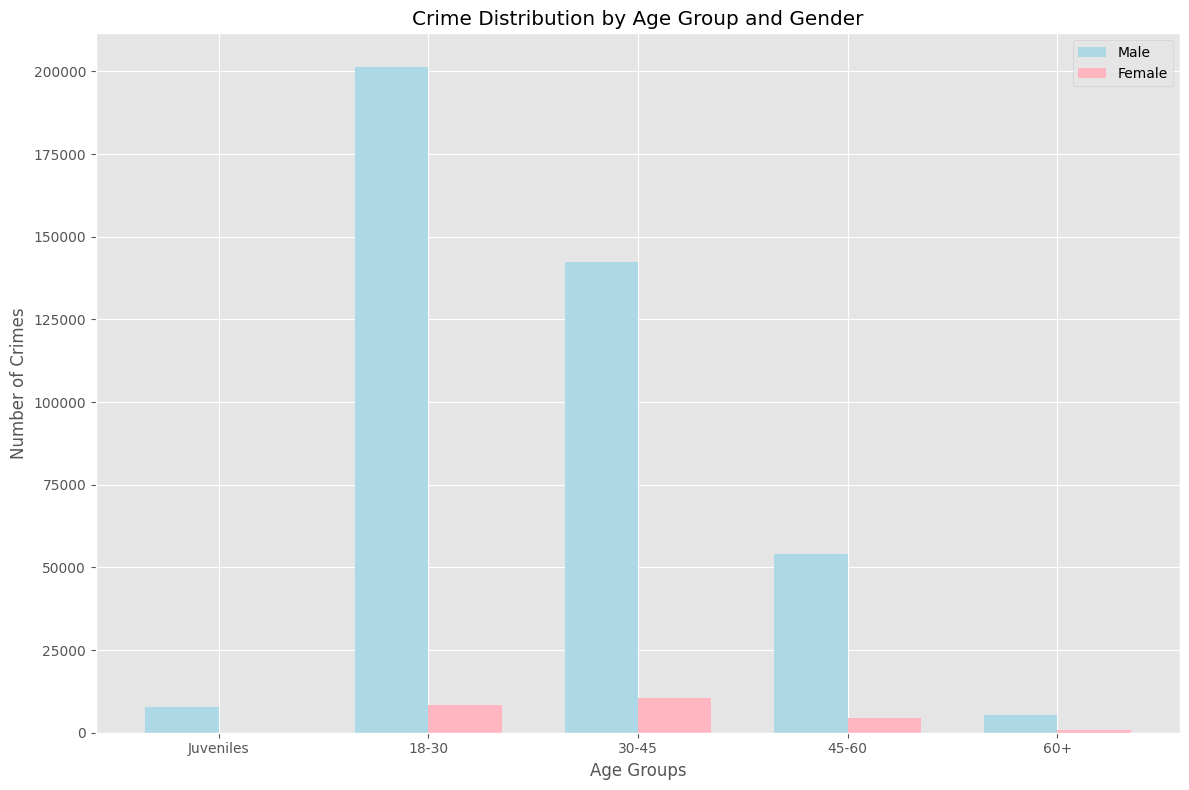

Age-wise Gender Distribution:
   Age Group    Male  Female
0  Juveniles    7790      16
1      18-30  201422    8432
2      30-45  142365   10451
3      45-60   54038    4347
4        60+    5235     673


In [18]:
# Gender comparison across age groups
age_gender_data = {
    'Age Group': ['Juveniles', '18-30', '30-45', '45-60', '60+'],
    'Male': [
        df[' Juveniles Apprehended - Boys'].sum(),
        df['18 and above and below 30 years - Male'].sum(),
        df['30 and above and below 45 years - Male'].sum(),
        df['45 and above and below 60 years - Male'].sum(),
        df['60 years and above - Male'].sum()
    ],
    'Female': [
        df[' Juveniles Apprehended - Girls'].sum(),
        df['18 and above and below 30 years - Female'].sum(),
        df['30 and above and below 45 years - Female'].sum(),
        df['45 and above and below 60 years - Female'].sum(),
        df['60 years and above - Female'].sum()
    ]
}

# Create DataFrame for easier plotting
age_gender_df = pd.DataFrame(age_gender_data)

# Grouped bar chart
plt.figure(figsize=(12, 8))
x = np.arange(len(age_gender_df['Age Group']))
width = 0.35

plt.bar(x - width/2, age_gender_df['Male'], width, label='Male', color='lightblue')
plt.bar(x + width/2, age_gender_df['Female'], width, label='Female', color='lightpink')

plt.xlabel('Age Groups')
plt.ylabel('Number of Crimes')
plt.title('Crime Distribution by Age Group and Gender')
plt.xticks(x, age_gender_df['Age Group'])
plt.legend()
plt.tight_layout()
plt.show()

# Display the data
print("Age-wise Gender Distribution:")
print(age_gender_df)

<Figure size 1200x800 with 0 Axes>

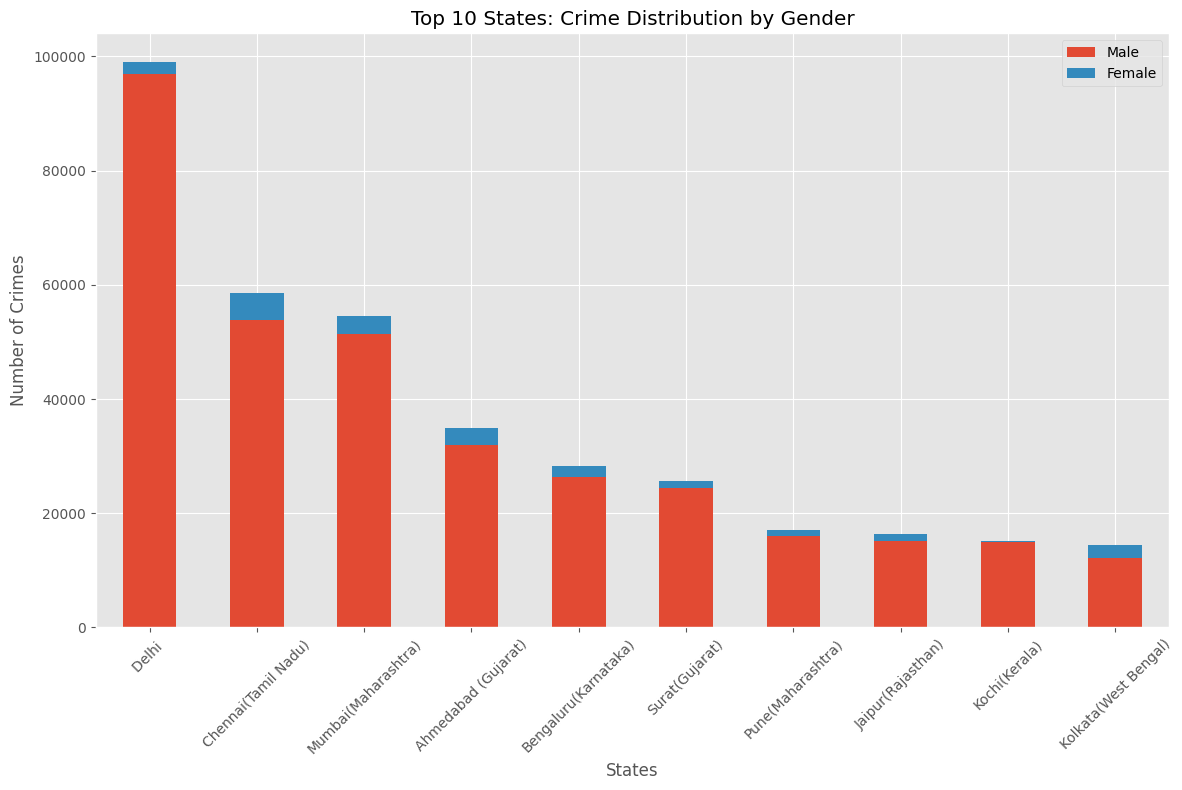

In [21]:
# Top 10 states by total crimes
state_crimes = df.groupby('City').agg({
    'Total   - Male': 'sum',
    'Total   - Female': 'sum'
})
state_crimes['Total'] = state_crimes['Total   - Male'] + state_crimes['Total   - Female']
state_crimes = state_crimes.sort_values('Total', ascending=False).head(10)

plt.figure(figsize=(12, 8))
state_crimes[['Total   - Male', 'Total   - Female']].plot(kind='bar', 
                                                            stacked=True, 
                                                            figsize=(12, 8))
plt.title('Top 10 States: Crime Distribution by Gender')
plt.ylabel('Number of Crimes')
plt.xlabel('States')
plt.xticks(rotation=45)
plt.legend(['Male', 'Female'])
plt.tight_layout()
plt.show()